# AICE 전체 흐름 함께 풀기 · 2026-11-19

**구독 서비스 고객의 해지 여부를 예측하는 분류 실습**

가상 데이터로 만든 14문항입니다. 실제 기출문제나 공식 채점 기준이 아닙니다. 이번에는 타이머 없이 한 문항씩 같이 진행합니다. 스스로 재도전할 때만 90분을 목표로 하세요.

CSV와 이 노트북을 같은 폴더에 저장하세요. 답안은 아래 빈 코드 셀에 직접 작성합니다. 준비 코드나 별도 채점 셀은 없습니다. 막힐 때만 각 문항의 힌트를 열어보세요. 그래프를 Figure 변수에 저장하라는 추가 조건은 없습니다.

**진행 순서:** 탐색 → 시각화 → 중복·이상치·결측치 → 인코딩 → 데이터 분리 → 스케일링 → 머신러닝 → 딥러닝 → 저장 모델 불러오기·평가.

전처리 순서는 이번 문제의 지시를 따릅니다. 실무의 엄격한 성능 검증에서는 중앙값·인코딩 등의 학습도 훈련 데이터에 한정하는 방식이 필요합니다.

## 컬럼 설명
|컬럼|뜻|
|---|---|
|customer_id|고객 식별번호. 모델 입력에서 제외|
|age|나이. 100 초과는 이 실습의 이상치|
|region|거주 지역|
|contract_type|Monthly/Annual 계약 유형|
|contact_channel|주 이용 채널 App/Phone/Web|
|tenure_months|이용 기간(개월)|
|monthly_fee|월 이용료(원)|
|weekly_usage_hours|주간 이용시간(시간)|
|support_calls|최근 고객지원 문의 횟수|
|past_satisfaction|이전에 응답한 만족도(1~5)|
|churn|예측할 정답. No=유지,Yes=해지|

필요 패키지: pandas,numpy,seaborn,matplotlib,scikit-learn,tensorflow. VS Code에서 사용 중인 가상환경을 노트북 커널로 선택하세요.


## 1. 라이브러리 호출

pandas를 pd, numpy를 np, seaborn을 sns, matplotlib.pyplot을 plt로 불러오세요.

<details><summary>힌트 보기</summary>

import 라이브러리 as 별칭

</details>


In [59]:
# 여기에 답안코드를 작성하고 실행하세요.
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

## 2. 파일 읽기와 기본 확인

aice_subscription.csv를 data로 읽고 처음 4행을 출력하세요. 행·열 개수는 shape_answer, 컬럼별 결측치 수는 missing_answer에 저장하세요.

<details><summary>힌트 보기</summary>

read_csv, head(4), shape, isna().sum()

</details>


In [ ]:
# 여기에 답안코드를 작성하고 실행하세요.
data = pd.read_csv("./aice_subscription.csv")
print(data.head(4))
shape_answer = data.shape
missing_answer = data.isna().sum()

In [61]:
print(shape_answer)
print(missing_answer)

(1008, 11)
customer_id            0
age                   19
region                 0
contract_type          0
contact_channel       18
tenure_months          0
monthly_fee            0
weekly_usage_hours    35
support_calls          0
past_satisfaction     30
churn                  0
dtype: int64


## 3. 범주 분포와 집계

contract_type의 countplot을 그리세요. 제목은 Contract Count. 계약 유형별 monthly_fee 평균을 fee_by_contract에 저장하세요.

<details><summary>힌트 보기</summary>

countplot(data=data,x=...). groupby(그룹)[수치열].mean()

</details>


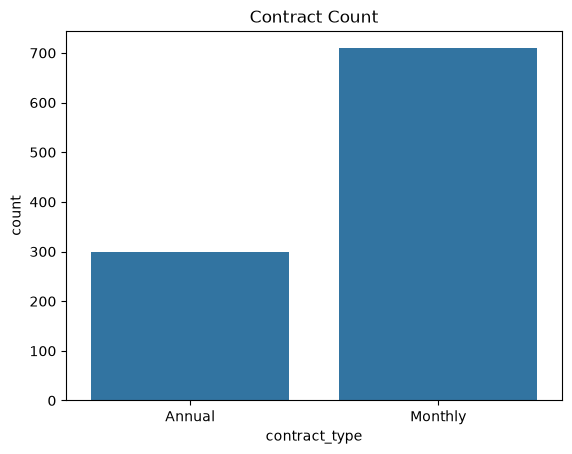

In [62]:
# 여기에 답안코드를 작성하고 실행하세요.
sns.countplot(data=data, x="contract_type")
plt.title("Contract Count")

fee_by_contract = data.groupby("contract_type")["monthly_fee"].mean()

## 4. 수치 분포 시각화

churn을 X축, past_satisfaction을 Y축으로 하는 boxplot을 그리세요.

<details><summary>힌트 보기</summary>

sns.boxplot의 x,y를 확인하세요. Figure를 별도 변수에 저장할 필요는 없습니다.

</details>


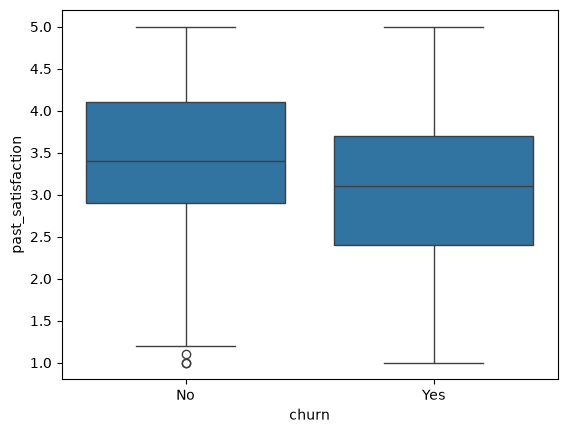

In [63]:
# 여기에 답안코드를 작성하고 실행하세요.
sns.boxplot(data=data, x="churn", y="past_satisfaction")
plt.show()

## 5. 중복·이상치·인덱스

완전히 동일한 중복 행을 제거하세요. age가 100을 초과하는 행을 제거하되 age 결측 행은 유지하세요. customer_id를 삭제하고 인덱스를 초기화한 결과를 data_temp에 저장하세요.

<details><summary>힌트 보기</summary>

isna() | (age <= 100), drop(columns=...), reset_index(drop=True)

</details>


In [64]:
# 여기에 답안코드를 작성하고 실행하세요.
data = data.drop_duplicates()
data = data[(data["age"]<=100)|(data["age"].isna())]
data_temp = data.drop(columns=["customer_id"]).reset_index(drop=True)

## 6. 결측치 대체

data_temp를 복사해 data_na를 만드세요. age와 weekly_usage_hours는 각 중앙값, past_satisfaction은 평균, contact_channel은 최빈값으로 채우세요. 전체 결측치 수가 0인지 출력하세요.

<details><summary>힌트 보기</summary>

문항의 평균/중앙값 지시를 구분하세요. mode().iloc[0]은 값 하나입니다.

</details>


In [65]:
# 여기에 답안코드를 작성하고 실행하세요.
data_na = data_temp.copy()

medians = ["age", "weekly_usage_hours"]

data_na[medians] = data_na[medians].fillna(data_na[medians].median())
data_na["past_satisfaction"] = data_na["past_satisfaction"].fillna(data_na["past_satisfaction"].mean())
data_na["contact_channel"] = data_na["contact_channel"].fillna(data_na["contact_channel"].mode().iloc[0])

data_na.isna().sum().sum()

np.int64(0)

## 7. 라벨 인코더 상태와 원핫

학습용 복사본 label_demo에서 contract_type → contact_channel 순서로 동일한 le를 반복 사용해 라벨 인코딩하세요. 각 fit 직후 classes_의 복사본을 class_maps 딕셔너리에 컬럼명으로 저장하세요. 별도로 data_na의 churn을 No:0,Yes:1로 바꾸고 region,contract_type,contact_channel을 원핫 인코딩한 결과를 data_preset에 저장하세요. 원핫은 dtype=int,drop_first=False.

<details><summary>힌트 보기</summary>

label_demo는 대응표 연습용이며 모델링에는 쓰지 않습니다. classes_.copy()는 반복문 안에서 저장하세요. get_dummies의 첫 인자는 전체 데이터프레임입니다.

</details>


In [79]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.preprocessing import LabelEncoder

label_demo = data_na.copy()

class_maps = {}
le = LabelEncoder()

demo_cols = ["contract_type", "contact_channel"]

for i in demo_cols:

    label_demo[i] = le.fit_transform(label_demo[i])
    class_maps[i] = le.classes_

data_na["churn"] = data_na["churn"].map({
    "No":0,
    "Yes":1
})

data_preset = pd.get_dummies(
    data_na,
    columns=["region","contract_type","contact_channel"],
    dtype=int,
    drop_first=False
)

class_maps

{'contract_type': array(['Annual', 'Monthly'], dtype=object),
 'contact_channel': array(['App', 'Phone', 'Web'], dtype=object)}

## 8. X/y와 훈련·검증 분리

data_preset에서 churn을 y, 나머지를 X에 저장하세요. test_size=0.2,random_state=42,stratify=y로 X_train,X_valid,y_train,y_valid를 만드세요.

<details><summary>힌트 보기</summary>

이번에는 결측치와 인코딩을 처리한 뒤 분리합니다.

</details>


In [67]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.model_selection import train_test_split

X = data_preset.drop(columns=["churn"])
y = data_preset["churn"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## 9. 스케일링 오류 수정

아래 답안 셀의 오류를 수정하세요. ss는 StandardScaler, 훈련 기준을 검증에도 적용하고 X_train_scaled,X_valid_scaled에 저장하세요.

<details><summary>힌트 보기</summary>

검증 데이터에서는 transform만 사용합니다.

</details>


In [68]:
# 아래 코드의 오류를 정정하고 실행하세요.
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()
X_train_scaled=ss.fit_transform(X_train)
X_valid_scaled=ss.transform(X_valid)


## 10. 두 머신러닝 모델과 GridSearch

LogisticRegression(max_iter=1000,random_state=42)을 lr에 생성해 스케일된 훈련으로 학습하세요. RandomForestClassifier(n_estimators=50,random_state=42)의 max_depth 후보[3,5],min_samples_split 후보[2,5]를 GridSearchCV(cv=3,scoring="accuracy",n_jobs=-1)로 탐색해 gs_rf에 저장하세요. RF 탐색은 스케일 전 X_train 사용.

<details><summary>힌트 보기</summary>

GridSearchCV를 생성한 다음 fit하세요. 후보는 딕셔너리의 리스트입니다.

</details>


In [69]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

lr = LogisticRegression(max_iter=1000, random_state=42)

lr.fit(X_train_scaled, y_train)

params = {
    "max_depth":[3,5],
    "min_samples_split":[2,5]
}

gs_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=50, random_state=42),
    params,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

gs_rf.fit(X_train, y_train);

## 11. 변수 중요도

gs_rf.best_estimator_의 중요도를 feature,importance 컬럼의 fi로 만들고, 중요도 내림차순 상위10개를 남기세요. 가로 막대그래프를 그리고 최고 변수명을 answer11에 저장하세요.

<details><summary>힌트 보기</summary>

변수명은 스케일 전 X_train.columns에서 가져오세요. 그래프 자체를 변수에 저장할 필요는 없습니다.

</details>


RandomForestClassifier(max_depth=5, n_estimators=50, random_state=42)


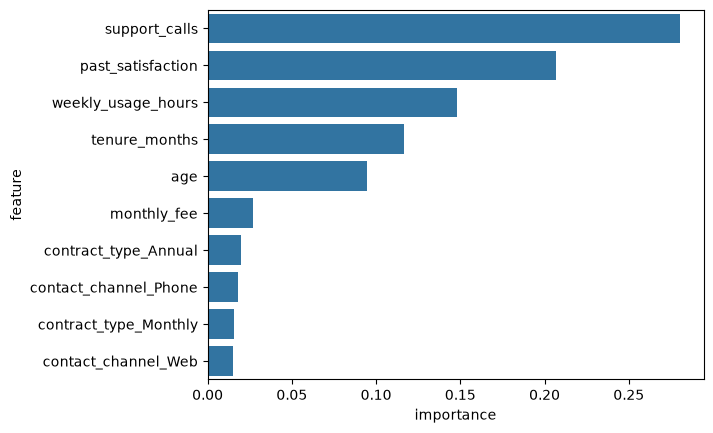

In [70]:
# 여기에 답안코드를 작성하고 실행하세요.
print(gs_rf.best_estimator_)
fi = pd.DataFrame({
    "feature":X_train.columns,
    "importance":gs_rf.best_estimator_.feature_importances_
}).sort_values("importance", ascending=False).head(10).reset_index(drop=True)

sns.barplot(data=fi, x="importance", y="feature")
plt.show()

answer11 = "support_calls"

## 12. 분류 평가와 확률

lr의 검증 클래스 예측은 pred_lr, RF 최적 모델의 검증 클래스 예측은 pred_rf에 저장하세요. RF의 클래스 순서를 확인하고 클래스1 확률을 proba_rf에 저장하세요. RF 혼동행렬·classification_report를 출력하고 ROC-AUC를 auc_rf에 저장하세요.

<details><summary>힌트 보기</summary>

ROC-AUC에는 확률, 혼동행렬에는 최종 클래스. RF에는 X_valid, lr에는 X_valid_scaled를 전달합니다.

</details>


In [71]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

pred_lr = lr.predict(X_valid_scaled)
pred_rf = gs_rf.predict(X_valid)
print(gs_rf.classes_)
proba_rf = gs_rf.predict_proba(X_valid)[:,1]

print(confusion_matrix(y_valid, pred_rf))
print(classification_report(y_valid, pred_rf, zero_division=0))
auc_rf = roc_auc_score(y_valid, proba_rf)


[0 1]
[[146   3]
 [ 49   1]]
              precision    recall  f1-score   support

           0       0.75      0.98      0.85       149
           1       0.25      0.02      0.04        50

    accuracy                           0.74       199
   macro avg       0.50      0.50      0.44       199
weighted avg       0.62      0.74      0.64       199



## 13. 딥러닝 학습·콜백

tensorflow.keras로 model을 구성하세요: 입력 특성 수 → Dense32 relu → Dropout0.2 → Dense16 relu → Dense1 sigmoid. adam,binary_crossentropy,accuracy로 컴파일하세요. estop은 val_loss,patience=5,restore_best_weights=True. checkpoint는 best_subscription.keras,val_loss,save_best_only=True. 스케일된 훈련으로 epochs=30,batch_size=32,validation_data=(X_valid_scaled,y_valid),callbacks 두 개를 사용해 학습하고 history에 저장하세요.

<details><summary>힌트 보기</summary>

정답은 정수0/1이고 출력은 sigmoid1개입니다. callbacks=[estop,checkpoint].

</details>


In [72]:
# 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

model = Sequential([
    # Input(shape=(X_train_scaled.shape[1],)), # 고객 한 명의 입력값 개수 지정
    Dense(32, activation="relu", input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.2), # 학습 중 전달값 약 20%를 무작위고 꺼 과적합을 줄임
    Dense(16, activation="relu"), 
    Dense(1, activation="sigmoid") # 확률을 숫자 하나로 출력 
])

model.summary()

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

estop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    monitor="val_loss",
    filepath="best_subscription.keras",
    save_best_only=True
)

c:\Users\LSG\Desktop\AICE\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 32)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,057 (4.13 KB)

 Trainable params: 1,057 (4.13 KB)

 Non-trainable params: 0 (0.00 B)

In [73]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_valid_scaled, y_valid),
    callbacks=[estop, checkpoint]
)

Epoch 1/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.4415 - loss: 0.7677 - val_accuracy: 0.6683 - val_loss: 0.6269
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6717 - loss: 0.6277 - val_accuracy: 0.7387 - val_loss: 0.5721
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7459 - loss: 0.5779 - val_accuracy: 0.7487 - val_loss: 0.5479
Epoch 4/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7472 - loss: 0.5599 - val_accuracy: 0.7487 - val_loss: 0.5337
Epoch 5/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7547 - loss: 0.5418 - val_accuracy: 0.7487 - val_loss: 0.5244
Epoch 6/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7547 - loss: 0.5410 - val_accuracy: 0.7487 - val_loss: 0.5184
Epoch 7/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7623 - loss: 0.5240 - val_accuracy: 0.7538 - val_loss: 0.5134
Epoch 8/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7748 - loss: 0.5198 - val_accuracy: 0.7487 - val_loss

## 14. 저장 모델·예측·학습 그래프

best_subscription.keras를 best_model로 불러오세요. 검증 데이터 예측 확률을 ravel해 dl_proba,0.5 이상을1로 변환해 dl_pred에 저장하세요. 혼동행렬과 ROC-AUC를 출력하세요. 이어 accuracy/val_accuracy를 한 그래프에 표시하세요. 범례 acc/val_acc,제목 Model Accuracy,축 Epoch/Accuracy.

<details><summary>힌트 보기</summary>

단일 sigmoid에서는 argmax가 아닌 기준값을 적용합니다. history.history의 두 키와 legend를 사용하세요.

</details>


In [74]:
# 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.models import load_model

best_model = load_model("best_subscription.keras")

dl_proba = best_model.predict(X_valid_scaled).ravel() # 원래 리스트 - 리스트 였으나, ravel 사용하면서 펴짐
print(dl_proba[:5])

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
[0.26280233 0.18530644 0.14306113 0.05452251 0.24090227]


In [75]:
dl_pred = (dl_proba >= 0.5).astype(int)
print(np.unique(dl_pred, return_counts=True))
print("최소·최대 확률:", dl_proba.min(), dl_proba.max())

(array([0, 1]), array([184,  15]))
최소·최대 확률: 0.024487544 0.7125323


In [76]:
from sklearn.metrics import confusion_matrix, roc_auc_score

print(confusion_matrix(y_valid, dl_pred))
print("ROC-AUC:", roc_auc_score(y_valid, dl_proba))

[[141   8]
 [ 43   7]]
ROC-AUC: 0.7573154362416108


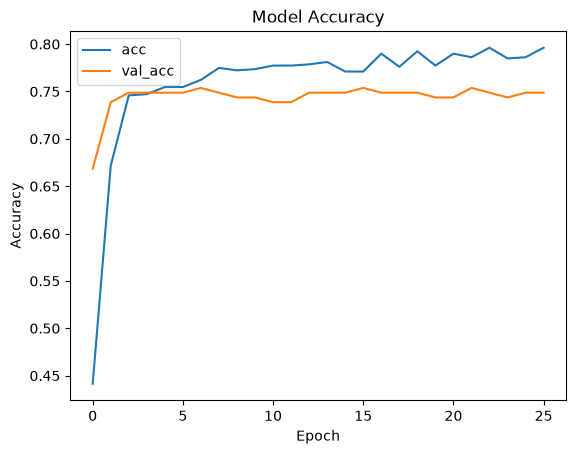

In [77]:
plt.plot(history.history["accuracy"], label="acc")
plt.plot(history.history["val_accuracy"], label="val_acc")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()